In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
#Importar os dados e verificar dimens~oes
df_train = pd.read_pickle('Xtrain.pkl')
#print(df_train.shape)
#Concatenar todas as poses e sequ^encias numa matriz de dados.
#Esta matriz vai ser usada na maior parte do projeto
X = np.concatenate(df_train['Skeleton_Sequence'].to_numpy())
#print(X.shape) # N X 66
#Normaliza¸c~ao dos dados - centrar + escalamento (recomendando e cr´ıtico para o PCA)
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)
#Aceder a uma sequ^encia espec´ıfica do dataframe, por exemplo a primeira
#seq = df_train.iloc[0]['Skeleton_Sequence']
#print(seq.shape) # T X 66





# Não MODIFICAR A SEED
np.random.seed(555)

def kminit(X, K, flag):
    #Inicialização - pode ser aleatória ou recorrendo ao k-means++
    # A inicialização do primeiro centróide é fixa
    N = X.shape[0]
    C = []
    primeiro = np.random.randint(N)
    C.append(X[primeiro])


    #complete o código para inicializar os K-1 centróides de acordo com a flag

    if flag == 'random':
        #o codigo já pos um centroide em C, faltam 
        retirarescolhido = np.delete(np.arange(N), primeiro)
        #sorteamos K-1 indices diferentes
        indices = np.random.choice(retirarescolhido, size=K-1, replace=False)
        #juntar a lista de centroides
        for idx in indices:
            C.append(X[idx])

    elif flag == 'km++':
        for _ in range(K-1):
            centroides_escolhidos = np.array(C)
            #distancia ao quadrado de cada ponto a cada centroide (N,m)
            distancia = np.sum((X[:, np.newaxis, :] - centroides_escolhidos[np.newaxis, :, :]) ** 2, axis=2)
            #distancia ao centroide + proximo
            minima_distancia = np.min(distancia, axis=1)
            probabilidade = minima_distancia/np.sum(minima_distancia)

            #sortear ponto
            idx = np.random.choice(N, p=probabilidade)
            C.append(X[idx])

    else:
        print("A flag deve ser random ou km++")

    return np.array(C)




def kmeans_custo(X, C, s):
#Calcula a funcão de custo do k-means
#centroide de cada ponto

    centros_atribuidos = C[s]

    #distancia euclidiana ao quadrado
    distancia_J = np.sum((X - centros_atribuidos)** 2, axis=1)
    #custo total
    J = np.sum(distancia_J)


#devolve a distancia ao quad de cada ponto ao seu centroide e a soma de tudo = J
    return distancia_J, J



#R1 iv - associar pontos aos centróides

def kmeans_atribuir(X,C):
    #Associa cada ponto ao centróide mais próximo.
    #distancia ao quadrado de cada ponto a cada centroide
    dist = np.sum((X[:, np.newaxis, :] - C[np.newaxis, :, :]) ** 2, axis=2)
    #indice do centroide + perto
    return np.argmin(dist, axis=1)


def kmeans(X, K, flag, max_iter=300, tol=1e-6):
#Aplica o algoritm k-means a matriz de dados X.
    N, d = X.shape

    #inicializar
    centroides = kminit(X, K, flag)
    J_inicial = None

    for _ in range(max_iter):
        #atribuição
        atribuir = kmeans_atribuir(X, centroides)

        #atualizar
        centroide_novo = np.zeros((K, d))
        for k in range(K):
            pontos_k = X[atribuir == k]
            if len(pontos_k) > 0:
                centroide_novo[k] = pontos_k.mean(axis=0)
            else:
                #cluster vazio - começa num ponto qualquer
                centroide_novo[k] = X[np.random.randint(N)]
        centroides = centroide_novo

        #paragem = J nao muda
        _, J_atual = kmeans_custo(X, centroides, atribuir)
        if J_inicial is not None and abs(J_inicial - J_atual) < tol: 
            break
        J_inicial = J_atual

    #atribuição final
    atribuir = kmeans_atribuir(X, centroides)
    return centroides, atribuir







In [2]:
centroides, atribuir = kmeans(X_norm, 5, 'km++')
print(centroides.shape, atribuir.shape, np.bincount(atribuir))
_, J = kmeans_custo(X_norm, centroides, atribuir)
print("J =", J)

(5, 66) (8374,) [ 719 5223  838 1202  392]
J = 205756.40423512345


K =  1  ->  J = 552684.00
K =  2  ->  J = 451679.55
K =  3  ->  J = 346002.62
K =  4  ->  J = 312576.68
K =  5  ->  J = 219189.00
K =  6  ->  J = 178013.86
K =  7  ->  J = 151110.33
K =  8  ->  J = 140598.14
K =  9  ->  J = 150472.60
K = 10  ->  J = 111804.27
K = 11  ->  J = 103934.26
K = 12  ->  J = 92466.38
K = 13  ->  J = 96161.73
K = 14  ->  J = 81090.81


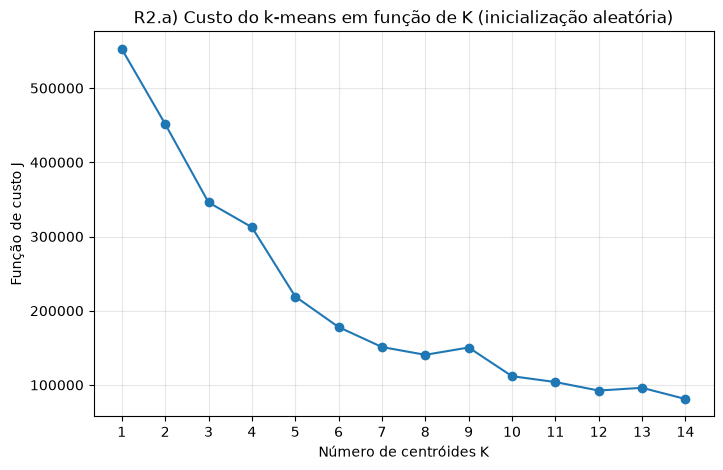

K =  1 ->  2: J desce 101004.45  ( 18.3%)
K =  2 ->  3: J desce 105676.93  ( 23.4%)
K =  3 ->  4: J desce  33425.94  (  9.7%)
K =  4 ->  5: J desce  93387.68  ( 29.9%)
K =  5 ->  6: J desce  41175.15  ( 18.8%)
K =  6 ->  7: J desce  26903.53  ( 15.1%)
K =  7 ->  8: J desce  10512.18  (  7.0%)
K =  8 ->  9: J desce  -9874.45  ( -7.0%)
K =  9 -> 10: J desce  38668.33  ( 25.7%)
K = 10 -> 11: J desce   7870.01  (  7.0%)
K = 11 -> 12: J desce  11467.87  ( 11.0%)
K = 12 -> 13: J desce  -3695.34  ( -4.0%)
K = 13 -> 14: J desce  15070.92  ( 15.7%)


In [3]:
import matplotlib.pyplot as plt

testar_k = range(1, 15)          # testar K de 1 a 15
custos_random = []

for K in testar_k:
    centroides, atribuir = kmeans(X_norm, K, 'random')
    _, J = kmeans_custo(X_norm, centroides, atribuir)
    custos_random.append(J)
    print(f"K = {K:2d}  ->  J = {J:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(testar_k, custos_random, 'o-')
plt.xlabel('Número de centróides K')
plt.ylabel('Função de custo J')
plt.title('R2.a) Custo do k-means em função de K (inicialização aleatória)')
plt.xticks(list(testar_k))
plt.grid(True, alpha=0.3)
plt.savefig('PartI_R2a.jpg', dpi=150, bbox_inches='tight')
plt.show()

# quanto o custo desce de K-1 para K (ajuda a encontrar o cotovelo)
ganhos = -np.diff(custos_random)
ganho_relativo = ganhos / np.array(custos_random[:-1]) * 100
for K, g, r in zip(list(testar_k)[1:], ganhos, ganho_relativo):
    print(f"K = {K-1:2d} -> {K:2d}: J desce {g:9.2f}  ({r:5.1f}%)")

K =  1  ->  J = 552684.00
K =  2  ->  J = 401477.00
K =  3  ->  J = 291317.89
K =  4  ->  J = 247808.31
K =  5  ->  J = 205756.40
K =  6  ->  J = 170150.58
K =  7  ->  J = 143062.32
K =  8  ->  J = 129793.62
K =  9  ->  J = 120380.97
K = 10  ->  J = 117648.38
K = 11  ->  J = 96171.89
K = 12  ->  J = 96768.65
K = 13  ->  J = 88546.39
K = 14  ->  J = 82274.55


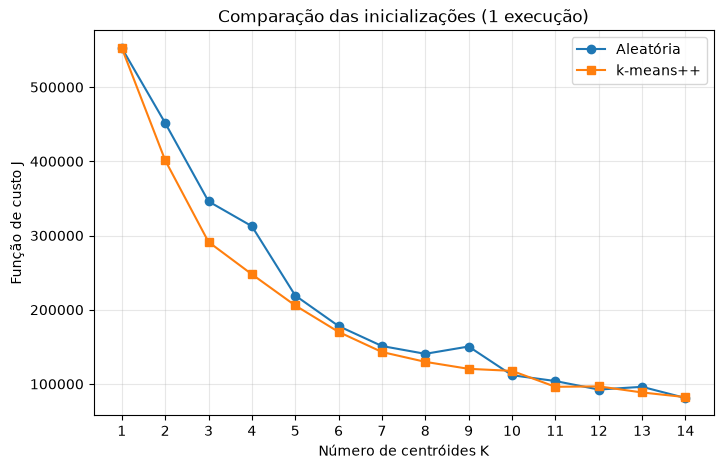

K =  1 ->  2: J desce 151207.00  ( 27.4%)
K =  2 ->  3: J desce 110159.11  ( 27.4%)
K =  3 ->  4: J desce  43509.58  ( 14.9%)
K =  4 ->  5: J desce  42051.91  ( 17.0%)
K =  5 ->  6: J desce  35605.82  ( 17.3%)
K =  6 ->  7: J desce  27088.26  ( 15.9%)
K =  7 ->  8: J desce  13268.70  (  9.3%)
K =  8 ->  9: J desce   9412.65  (  7.3%)
K =  9 -> 10: J desce   2732.59  (  2.3%)
K = 10 -> 11: J desce  21476.49  ( 18.3%)
K = 11 -> 12: J desce   -596.77  ( -0.6%)
K = 12 -> 13: J desce   8222.27  (  8.5%)
K = 13 -> 14: J desce   6271.84  (  7.1%)


In [4]:
#custo x K, inicialização k-means++ 
custos_kmpp = []

for K in testar_k:
    centroides, atribuir = kmeans(X_norm, K, 'km++')
    _, J = kmeans_custo(X_norm, centroides, atribuir)
    custos_kmpp.append(J)
    print(f"K = {K:2d}  ->  J = {J:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(testar_k, custos_random, 'o-', label='Aleatória')
plt.plot(testar_k, custos_kmpp, 's-', label='k-means++')
plt.xlabel('Número de centróides K')
plt.ylabel('Função de custo J')
plt.title('Comparação das inicializações (1 execução)')
plt.xticks(list(testar_k))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# quanto o custo desce de K-1 para K
ganhos = -np.diff(custos_kmpp)
ganho_relativo = ganhos / np.array(custos_kmpp[:-1]) * 100
for K, g, r in zip(list(testar_k)[1:], ganhos, ganho_relativo):
    print(f"K = {K-1:2d} -> {K:2d}: J desce {g:9.2f}  ({r:5.1f}%)")

execução 1/20 concluída
execução 2/20 concluída
execução 3/20 concluída
execução 4/20 concluída
execução 5/20 concluída
execução 6/20 concluída
execução 7/20 concluída
execução 8/20 concluída
execução 9/20 concluída
execução 10/20 concluída
execução 11/20 concluída
execução 12/20 concluída
execução 13/20 concluída
execução 14/20 concluída
execução 15/20 concluída
execução 16/20 concluída
execução 17/20 concluída
execução 18/20 concluída
execução 19/20 concluída
execução 20/20 concluída


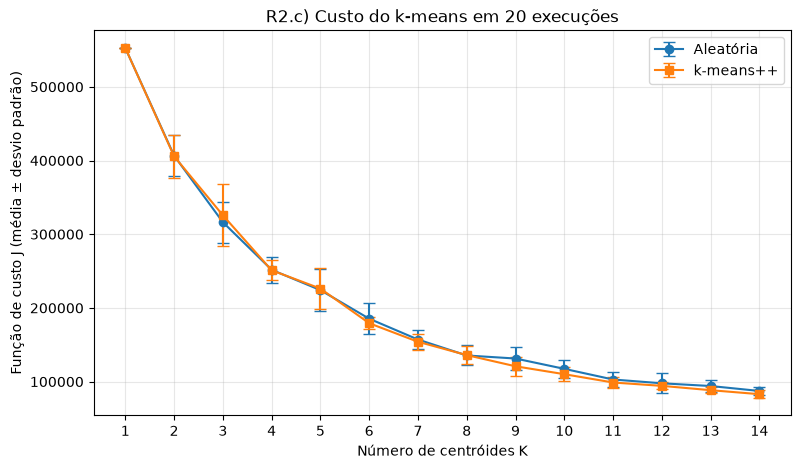

 K |  média aleat. |  dp aleat. |  média km++ |   dp km++
 1 |      552684.0 |        0.0 |    552684.0 |       0.0
 2 |      406653.7 |    27736.3 |    405743.0 |   29151.3
 3 |      316341.5 |    27755.3 |    325704.0 |   42043.2
 4 |      251708.6 |    17740.5 |    251057.9 |   13771.7
 5 |      224151.0 |    28056.4 |    226230.9 |   27885.4
 6 |      185368.3 |    21391.9 |    179233.8 |    8110.3
 7 |      157105.3 |    12659.5 |    154078.1 |   10849.7
 8 |      135479.9 |    13558.2 |    135981.0 |   12170.2
 9 |      131341.6 |    15515.7 |    120813.2 |   13121.4
10 |      117334.4 |    12551.0 |    110081.0 |    9372.3
11 |      102876.4 |     9625.9 |     98798.5 |    7197.7
12 |       97728.3 |    13433.4 |     94256.7 |    4715.7
13 |       94036.2 |     8718.8 |     88379.7 |    3810.2
14 |       87327.6 |     5569.9 |     82968.2 |    5182.7


In [5]:
#20 execsde cada inicialização 
n_runs = 20
testar_k_lista = list(testar_k)

J_random = np.zeros((n_runs, len(testar_k_lista)))   # linhas = execuções, colunas = K
J_kmpp   = np.zeros((n_runs, len(testar_k_lista)))

for r in range(n_runs):
    for i, K in enumerate(testar_k_lista):
        centroides, atribuir = kmeans(X_norm, K, 'random')
        _, J_random[r, i] = kmeans_custo(X_norm, centroides, atribuir)

        centroides, atribuir = kmeans(X_norm, K, 'km++')
        _, J_kmpp[r, i] = kmeans_custo(X_norm, centroides, atribuir)
    print(f"execução {r+1}/{n_runs} concluída")

# média e desvio padrão para cada K (ao longo das 20 execuções)
media_rand, dp_rand = J_random.mean(axis=0), J_random.std(axis=0)
media_kpp,  dp_kpp  = J_kmpp.mean(axis=0),   J_kmpp.std(axis=0)

plt.figure(figsize=(9, 5))
plt.errorbar(testar_k_lista, media_rand, yerr=dp_rand, fmt='o-', capsize=4, label='Aleatória')
plt.errorbar(testar_k_lista, media_kpp,  yerr=dp_kpp,  fmt='s-', capsize=4, label='k-means++')
plt.xlabel('Número de centróides K')
plt.ylabel('Função de custo J (média ± desvio padrão)')
plt.title('R2.c) Custo do k-means em 20 execuções')
plt.xticks(testar_k_lista)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('PartI_R2c.jpg', dpi=150, bbox_inches='tight')
plt.show()

print(" K |  média aleat. |  dp aleat. |  média km++ |   dp km++")
for i, K in enumerate(testar_k_lista):
    print(f"{K:2d} | {media_rand[i]:13.1f} | {dp_rand[i]:10.1f} | {media_kpp[i]:11.1f} | {dp_kpp[i]:9.1f}")

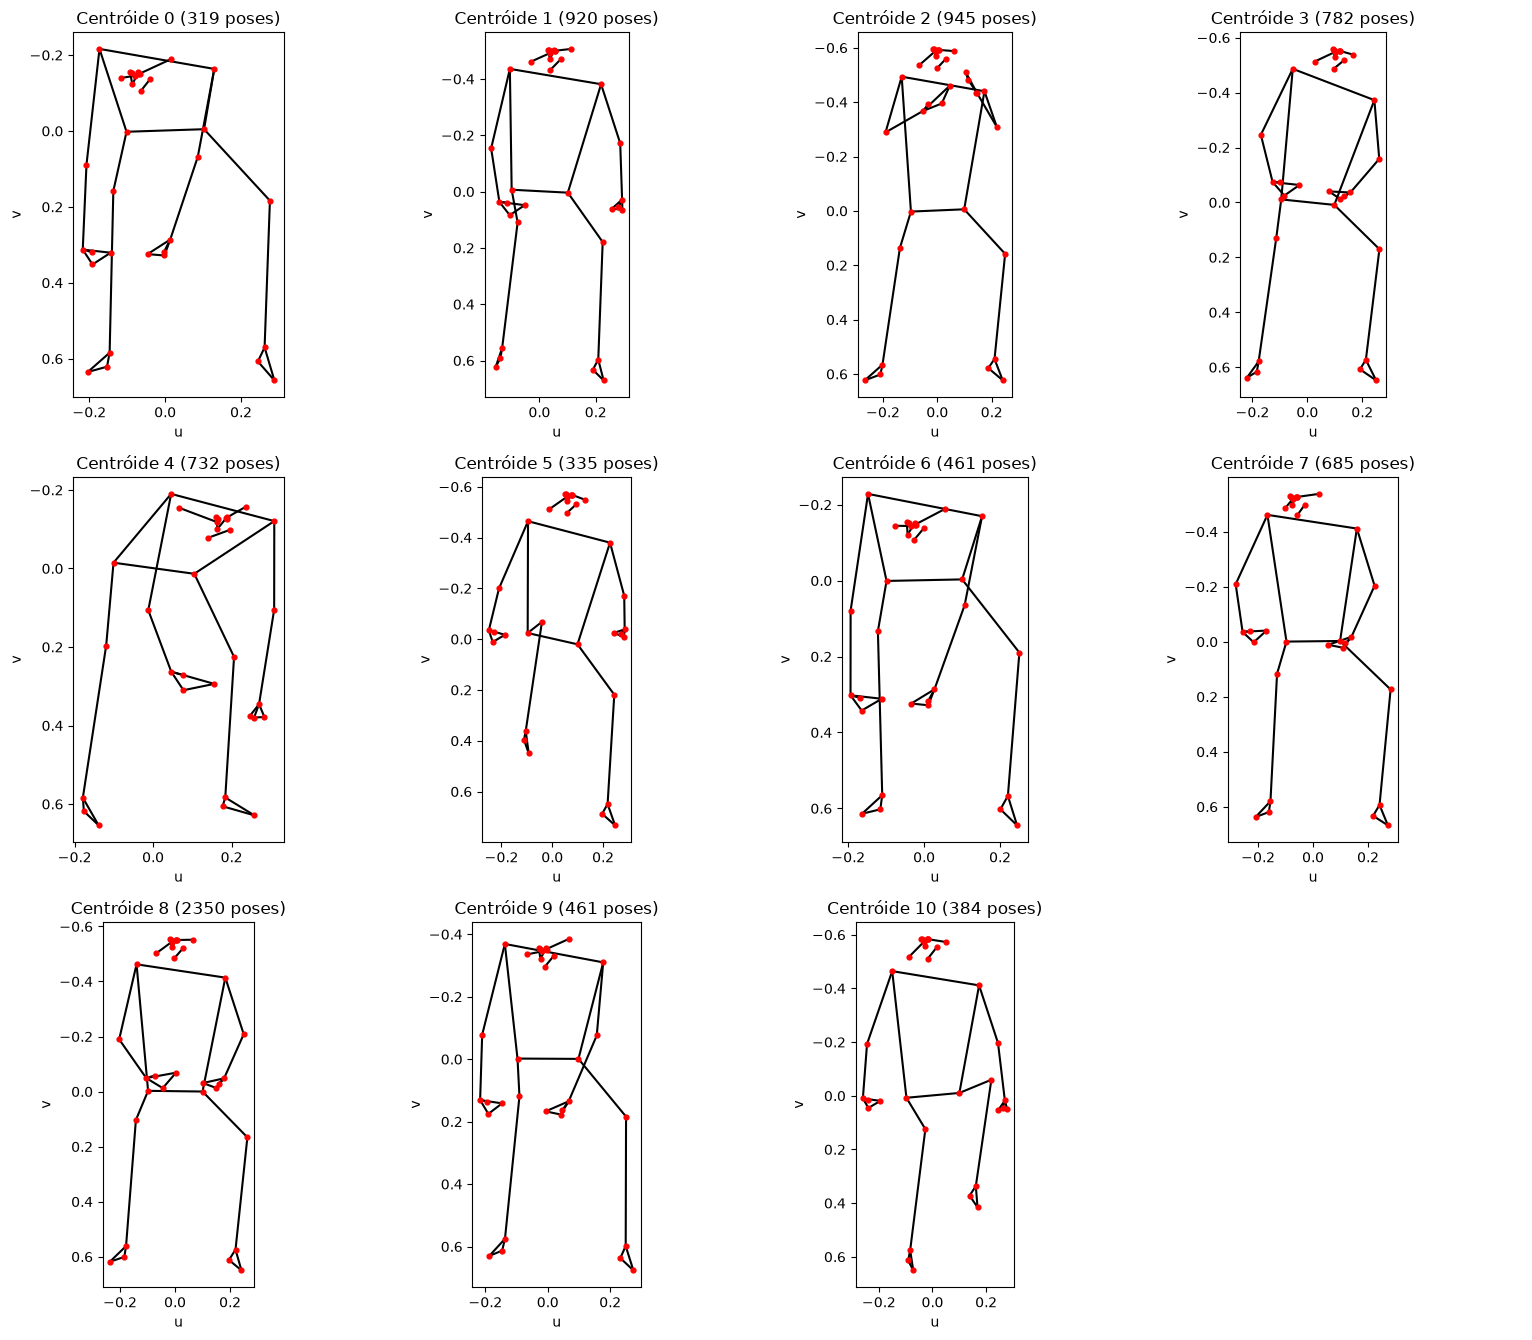

In [ ]:
# visualização das poses dos centróides 
LIGACOES = [
    # cara
    (0, 1), (1, 2), (2, 3), (3, 7), (0, 4), (4, 5), (5, 6), (6, 8), (9, 10),
    # tronco
    (11, 12), (11, 23), (12, 24), (23, 24),
    # braço (11) e mão
    (11, 13), (13, 15), (15, 17), (15, 19), (15, 21), (17, 19),
    # braço (12) e mão
    (12, 14), (14, 16), (16, 18), (16, 20), (16, 22), (18, 20),
    # perna (23) e pé
    (23, 25), (25, 27), (27, 29), (29, 31), (27, 31),
    # perna (24) e pé
    (24, 26), (26, 28), (28, 30), (30, 32), (28, 32),
]

def desenhar_pose(pose, ax, titulo=None):
    # pose = [u0, v0, u1, v1, ..., u32, v32]
    u = pose[0::2]     #par -> coordenadas u
    v = pose[1::2]     #ímpar -> coordenadas v
    for a, b in LIGACOES:
        ax.plot([u[a], u[b]], [v[a], v[b]], 'k-', lw=1.5)
    ax.scatter(u, v, c='red', s=12, zorder=3)
    ax.set_aspect('equal')
    ax.invert_yaxis()            # em imagem, v cresce para baixo
    ax.set_xlabel('u')
    ax.set_ylabel('v')
    if titulo:
        ax.set_title(titulo)


# centróides do modelo escolhido 
K_escolhido = 11
init_escolhida = 'km++'

centroides, atribuir = kmeans(X_norm, K_escolhido, init_escolhida)
centroides_reais = scaler.inverse_transform(centroides)   # desfazer a normalização
tamanhos = np.bincount(atribuir, minlength=K_escolhido)

n_cols = 4
n_rows = int(np.ceil(K_escolhido / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4.5 * n_rows), sharex=True, sharey=True)
axes = axes.ravel()

for k in range(K_escolhido):
    desenhar_pose(centroides_reais[k], axes[k], f'Centróide {k} ({tamanhos[k]} poses)')
for ax in axes[K_escolhido:]:
    ax.axis('off')       # esconder os quadrados vazios

plt.tight_layout()
plt.savefig('PartI_R3a.jpg', dpi=150, bbox_inches='tight')
plt.show()

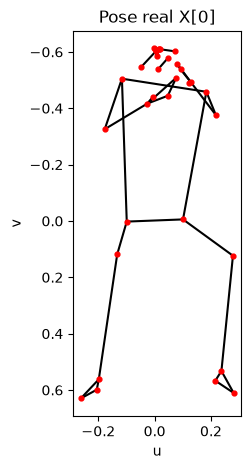